# IC distribuida: ampliar de 2000 a 5000 pasos de continuación

**Pregunta:** ¿la diferencia entre Sobol y POD/PCA depende de entrenar durante más tiempo?

Se mantiene el protocolo corregido: 32 nodos IC distribuidos por todo el dominio, 10 semillas y tres selectores, con 128 puntos físicos activos y actualización cada 100 pasos. Los 100 pasos de calentamiento se suman a los 5000 de continuación: **5100 pasos totales**.

Al presupuesto final, el menor RMSE medio de prueba corresponde a **Sobol** (0.0913). La comparación completa incluye residuo, condición inicial y frontera. La mayor diferencia numérica en el prefijo auditado es **0**.

## 1. Protocolo fijado antes de ejecutar

| Elemento | Configuración |
|---|---|
| IC | Los mismos 32 índices equiespaciados, incluidos ambos extremos |
| Sobol | 128 puntos Sobol activos |
| POD 32 | 32 puntos guiados por modos + 96 Sobol |
| PCA 64 | 64 puntos guiados por modos + 64 Sobol |
| Objetivo | Datos + física + IC, pesos 1/1/1; sin penalización separada de frontera |
| Optimización | Misma arquitectura, Adam y tasa de aprendizaje |
| Validación | Cada 100 pasos, sin detener ni cambiar pesos a partir de la prueba |
| Prueba numérica | Pasos totales 2100, 3100, 4100 y 5100, iguales para los tres métodos |

La corrida previa guardó parámetros, pero no todos los momentos de Adam. Se repite desde la inicialización determinista y se conserva continuamente el estado del optimizador durante esta ejecución; no se reinicia Adam en el paso 2100. Los mismos lotes aleatorios, historia residual y puntos activos del prefijo se auditan frente a la referencia. Las sondas, candidatos, nodos IC y particiones de ajuste/validación/prueba se conservan por semilla.

Los mapas pueden mostrar todos los tiempos para exploración. Las tablas de prueba se calculan exclusivamente en los presupuestos fijados; no se buscan retrospectivamente pesos o checkpoints con la prueba.

## 2. Precisión a presupuestos iguales

| Pasos continuación / totales | Sobol | POD 32 | PCA 64 |
|---|---:|---:|---:|
| 2000 / 2100 | 0.1734 ± 0.0362 | 0.1864 ± 0.0432 | 0.2051 ± 0.0322 |
| 3000 / 3100 | 0.1296 ± 0.0331 | 0.1603 ± 0.0480 | 0.1625 ± 0.0418 |
| 4000 / 4100 | 0.1069 ± 0.0317 | 0.1475 ± 0.0468 | 0.1416 ± 0.0365 |
| 5000 / 5100 | 0.0913 ± 0.0251 | 0.1188 ± 0.0215 | 0.1289 ± 0.0290 |

RMSE de solución en tiempos de prueba reservados. Los valores son media ± DE entre semillas, no intervalos de confianza.

| Método | Δ RMSE final − referencia | Semillas que mejoran | Δ residuo RMS | Δ IC global |
|---|---:|---:|---:|---:|
| Sobol | -0.0821 ± 0.0295 | 10/10 | -0.1246 ± 0.1542 | -0.0412 ± 0.0108 |
| POD: 32 puntos | -0.0676 ± 0.0293 | 10/10 | -0.0825 ± 0.0187 | -0.0269 ± 0.0230 |
| PCA + media: 64 puntos | -0.0763 ± 0.0234 | 10/10 | -0.0735 ± 0.0208 | -0.0343 ± 0.0280 |

Cada cambio se calcula primero dentro de la misma semilla, tomando 2100 pasos como referencia. Un valor negativo indica mejora. Entrenar más puede mejorar una métrica y empeorar otra.

**Comparación de precisión, residuo e IC a presupuestos iguales**

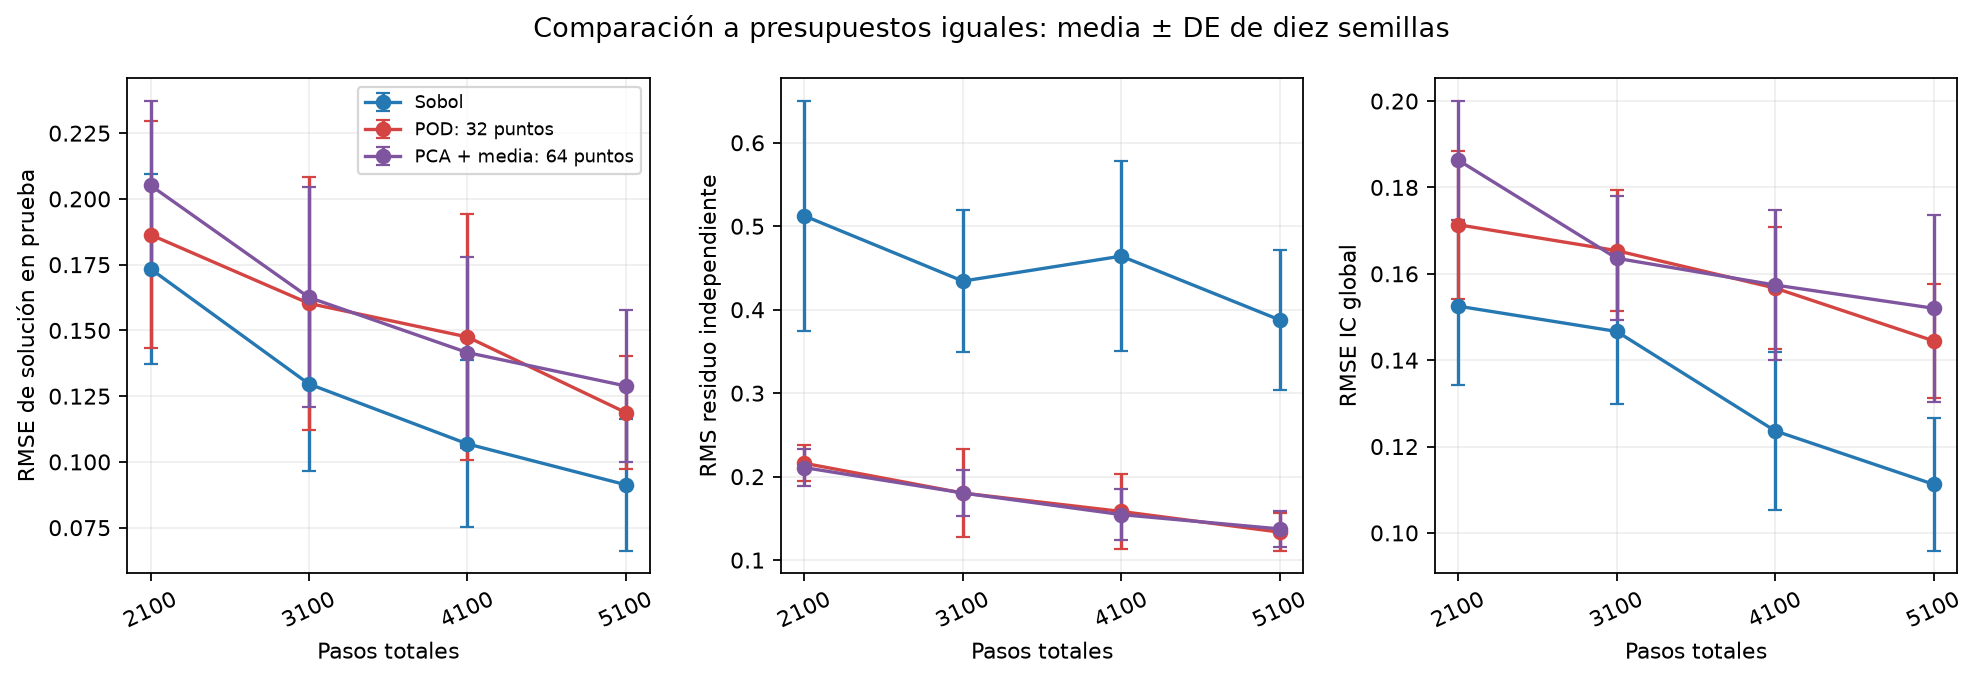

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/fixed_budget_comparison.png'), format='png', embed=True))


## 3. ¿POD/PCA alcanza a Sobol?

| Pasos totales | Método | Δ RMSE frente a Sobol | Semillas con menor RMSE que Sobol |
|---|---|---:|---:|
| 2100 | POD: 32 puntos | 0.0130 ± 0.0408 | 4/10 |
| 2100 | PCA + media: 64 puntos | 0.0317 ± 0.0492 | 2/10 |
| 3100 | POD: 32 puntos | 0.0306 ± 0.0536 | 3/10 |
| 3100 | PCA + media: 64 puntos | 0.0329 ± 0.0538 | 3/10 |
| 4100 | POD: 32 puntos | 0.0407 ± 0.0513 | 2/10 |
| 4100 | PCA + media: 64 puntos | 0.0347 ± 0.0382 | 1/10 |
| 5100 | POD: 32 puntos | 0.0275 ± 0.0249 | 2/10 |
| 5100 | PCA + media: 64 puntos | 0.0376 ± 0.0342 | 1/10 |

Δ = RMSE del método guiado − RMSE de Sobol, en la misma semilla y presupuesto. Un valor negativo favorece al método guiado. Las barras de la figura son medias; los puntos conservan la variabilidad entre semillas. La mejor media de una corrida no establece superioridad general.

**Diferencias pareadas frente a Sobol**

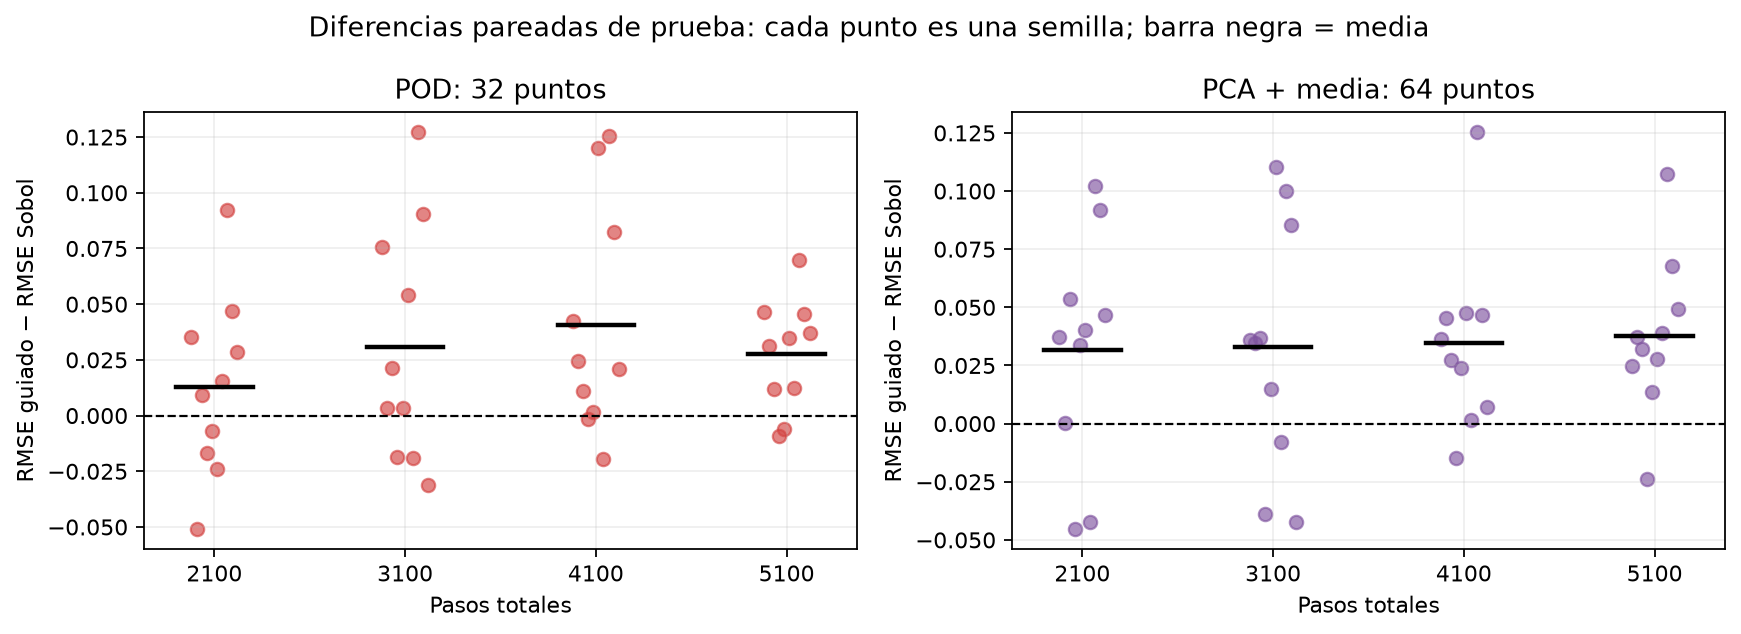

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/paired_test_gaps.png'), format='png', embed=True))


## 4. Cumplimiento físico y de las condiciones

### Residuo RMS independiente

| Pasos continuación / totales | Sobol | POD 32 | PCA 64 |
|---|---:|---:|---:|
| 2000 / 2100 | 0.5124 ± 0.1381 | 0.2160 ± 0.0218 | 0.2108 ± 0.0217 |
| 3000 / 3100 | 0.4343 ± 0.0855 | 0.1803 ± 0.0532 | 0.1804 ± 0.0275 |
| 4000 / 4100 | 0.4642 ± 0.1139 | 0.1583 ± 0.0446 | 0.1545 ± 0.0306 |
| 5000 / 5100 | 0.3877 ± 0.0839 | 0.1335 ± 0.0225 | 0.1374 ± 0.0212 |

### Error IC global

| Pasos continuación / totales | Sobol | POD 32 | PCA 64 |
|---|---:|---:|---:|
| 2000 / 2100 | 0.1525 ± 0.0183 | 0.1714 ± 0.0171 | 0.1863 ± 0.0138 |
| 3000 / 3100 | 0.1466 ± 0.0169 | 0.1654 ± 0.0141 | 0.1636 ± 0.0143 |
| 4000 / 4100 | 0.1236 ± 0.0183 | 0.1567 ± 0.0142 | 0.1574 ± 0.0175 |
| 5000 / 5100 | 0.1113 ± 0.0154 | 0.1445 ± 0.0132 | 0.1520 ± 0.0216 |

### RMS de frontera

| Pasos continuación / totales | Sobol | POD 32 | PCA 64 |
|---|---:|---:|---:|
| 2000 / 2100 | 0.1182 ± 0.0186 | 0.1026 ± 0.0168 | 0.0880 ± 0.0170 |
| 3000 / 3100 | 0.1034 ± 0.0125 | 0.0906 ± 0.0157 | 0.0806 ± 0.0169 |
| 4000 / 4100 | 0.0847 ± 0.0118 | 0.0805 ± 0.0103 | 0.0729 ± 0.0107 |
| 5000 / 5100 | 0.0742 ± 0.0109 | 0.0719 ± 0.0123 | 0.0669 ± 0.0120 |

La IC global usa todos los nodos espaciales; el residuo físico usa 2048 puntos independientes. La frontera se evalúa en tiempos de prueba y no se penaliza con un término separado en el objetivo. Los nodos IC siguen siendo 32 puntos discretos, no una imposición exacta en todo el continuo.

**Evolución de los monitores independientes**

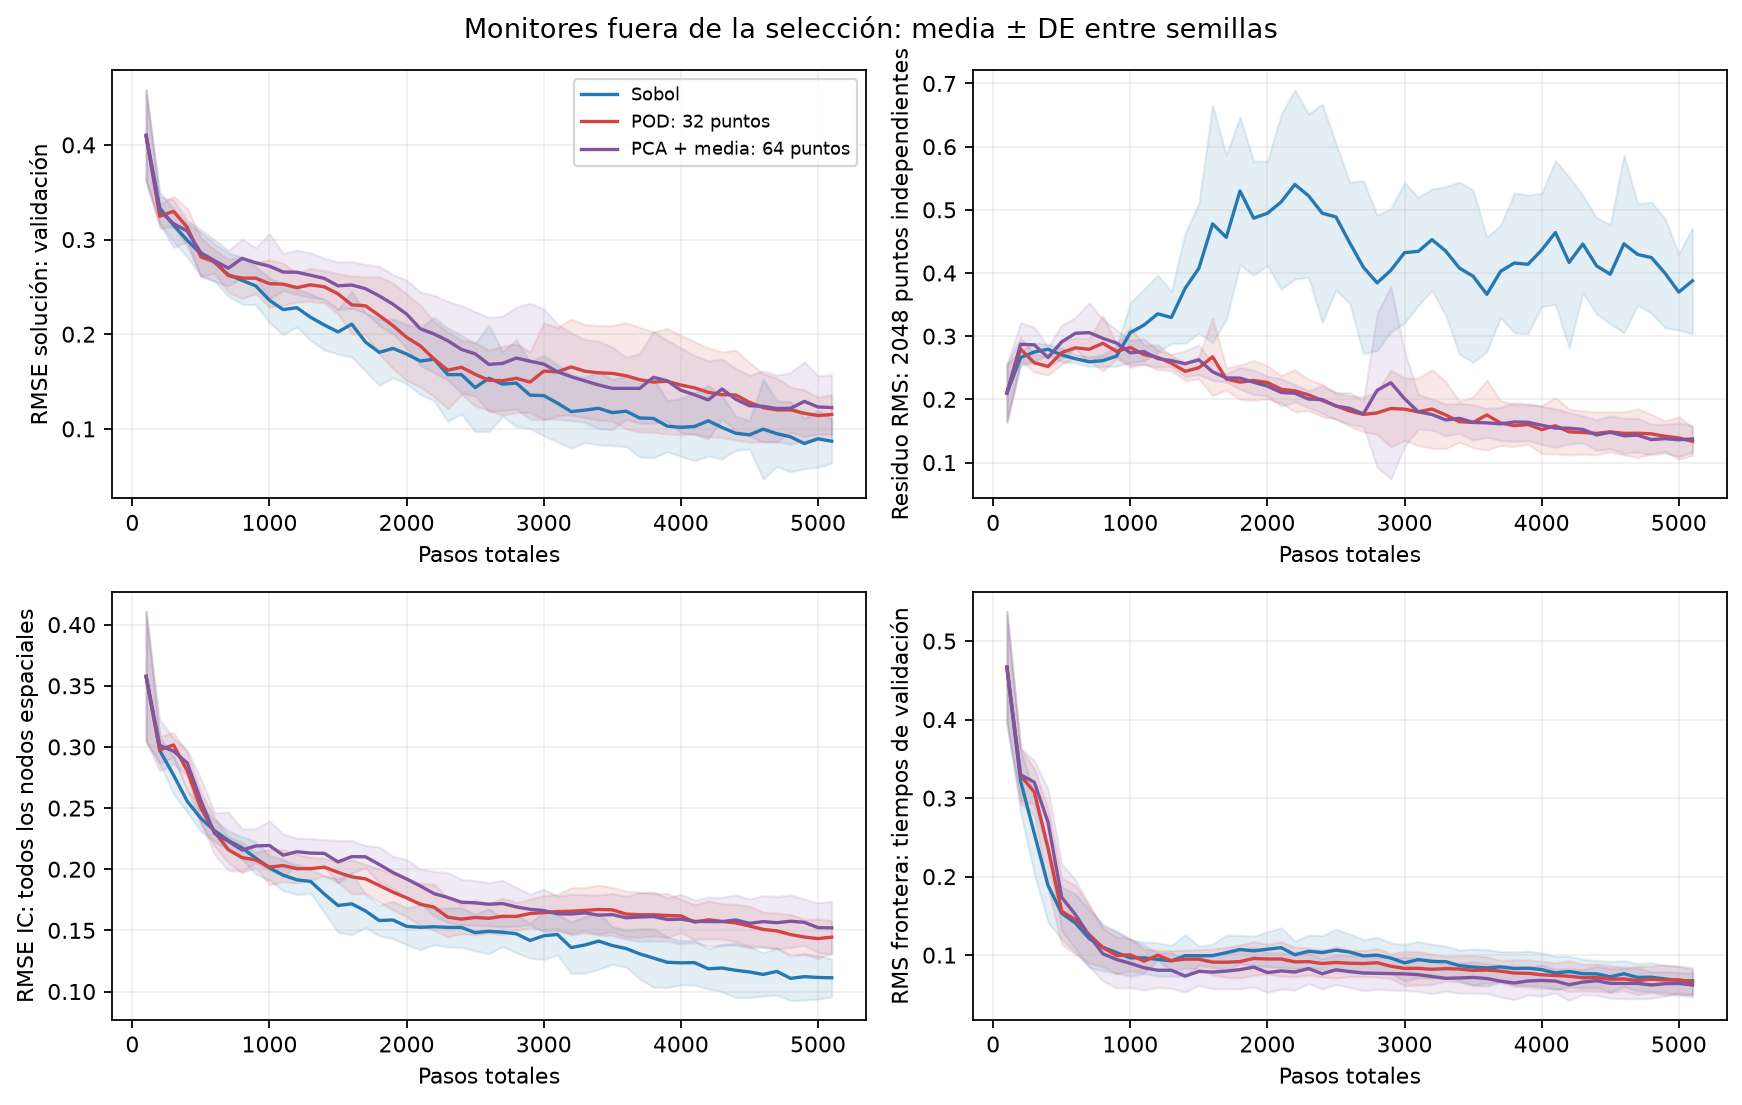

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/independent_monitors.png'), format='png', embed=True))


## 5. ¿Se observa una meseta al final?

| Método | Δ validación en los últimos 500 pasos | Semillas que mejoran |
|---|---:|---:|
| Sobol | -0.0128 ± 0.0327 | 6/10 |
| POD: 32 puntos | -0.0072 ± 0.0180 | 7/10 |
| PCA + media: 64 puntos | -0.0012 ± 0.0125 | 6/10 |

Este resumen compara validación entre los pasos 4600 y 5100. Es descriptivo; el presupuesto final se fijó antes de observarlo. Una mejora media pequeña puede ocultar diferencias entre semillas.

## 6. Campos, gradientes y selección

Las figuras detalladas usan la semilla 2051, fijada previamente. Los mapas antes/después comparten escala. Las curvas de pérdidas y gradientes usan las mismas sondas del diagnóstico; sus normas euclídeas no incorporan el precondicionamiento de Adam y los cosenos no prueban causalidad.

**Error con 2100 y 5100 pasos**

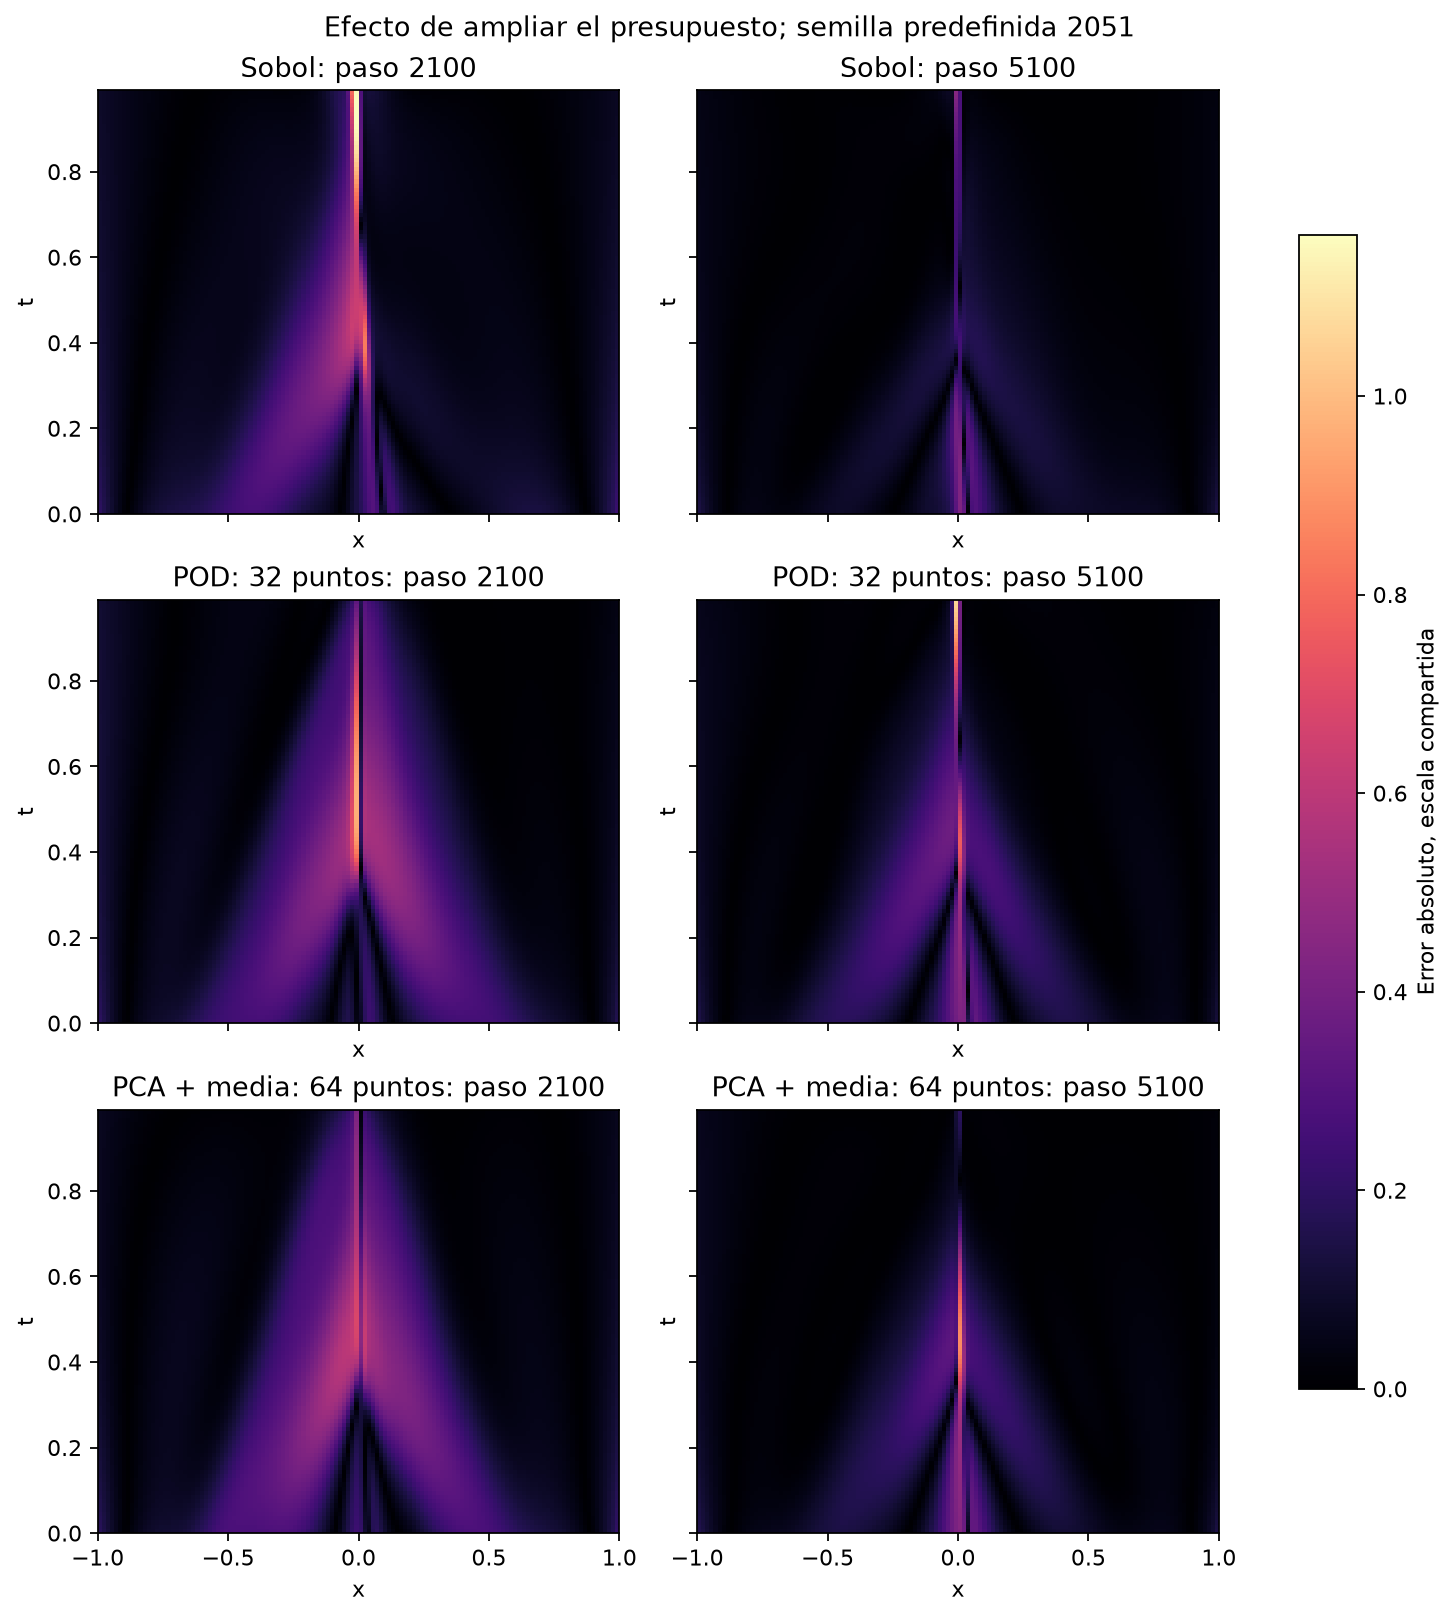

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/error_2100_vs_5100.png'), format='png', embed=True))


**Perfiles de la solución final**

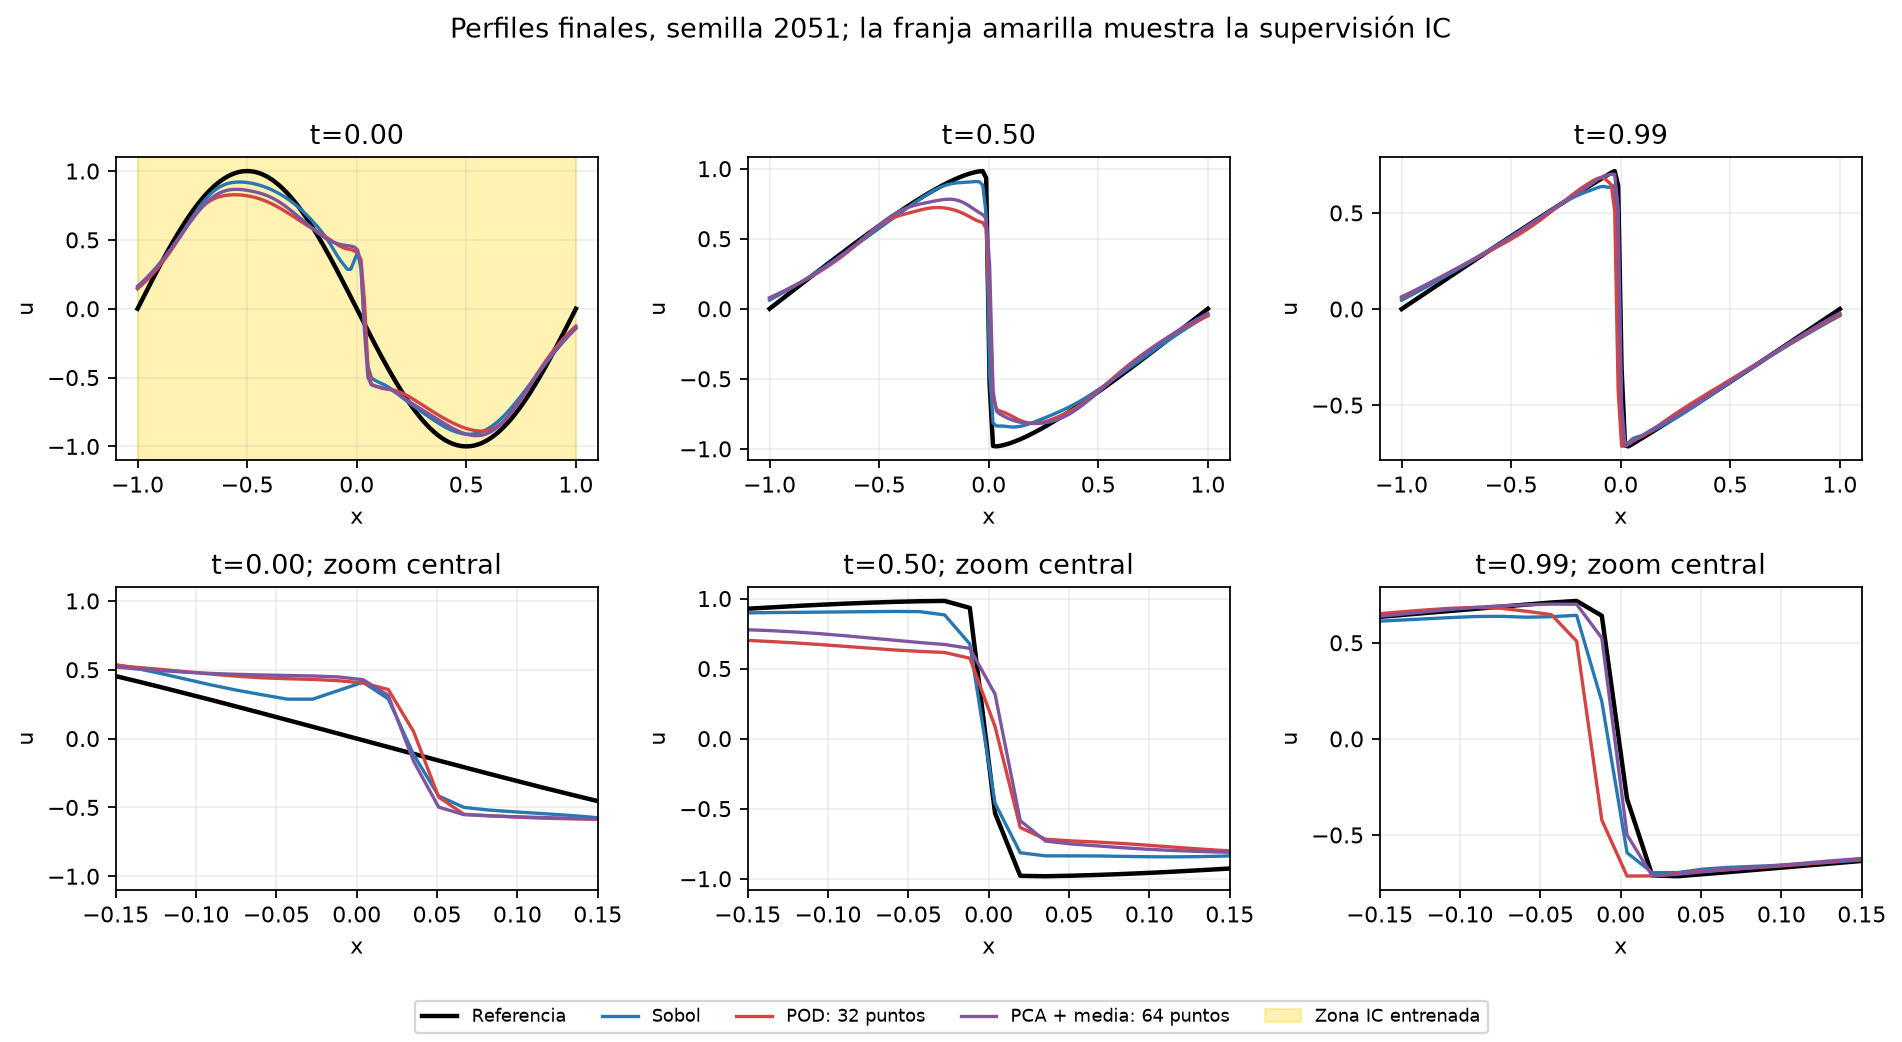

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/solution_profiles.png'), format='png', embed=True))


**Pérdidas separadas durante la extensión**

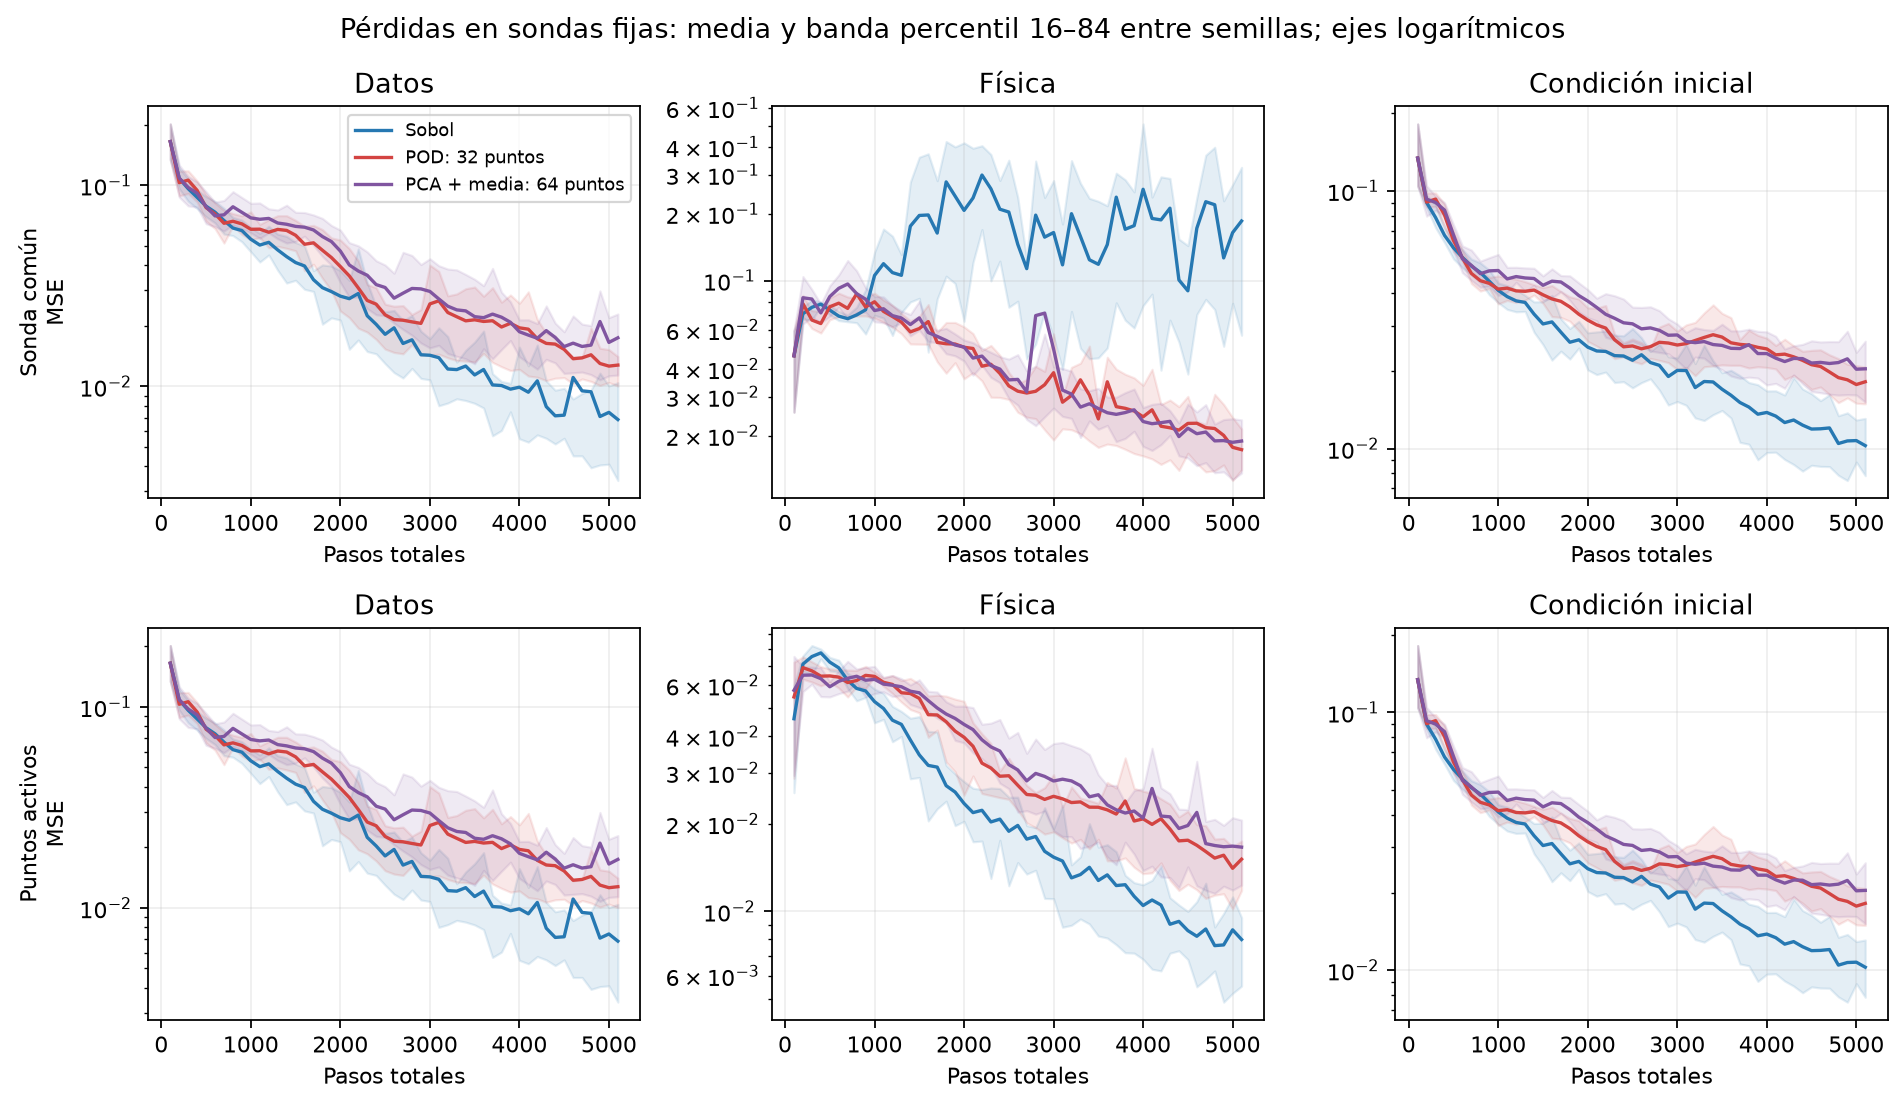

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/loss_components.png'), format='png', embed=True))


**Oposición local de gradientes**

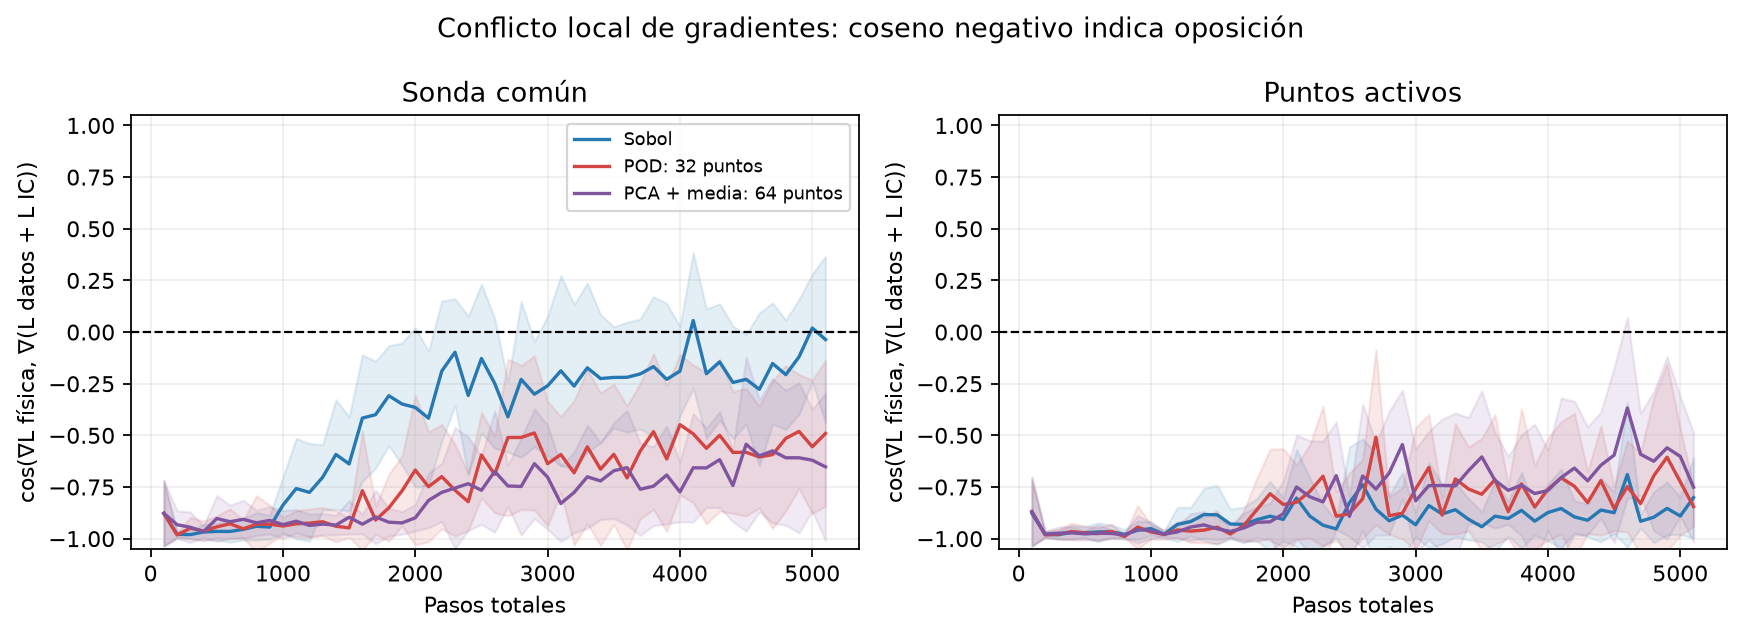

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/gradient_conflict.png'), format='png', embed=True))


**Evolución de los puntos de colocación**

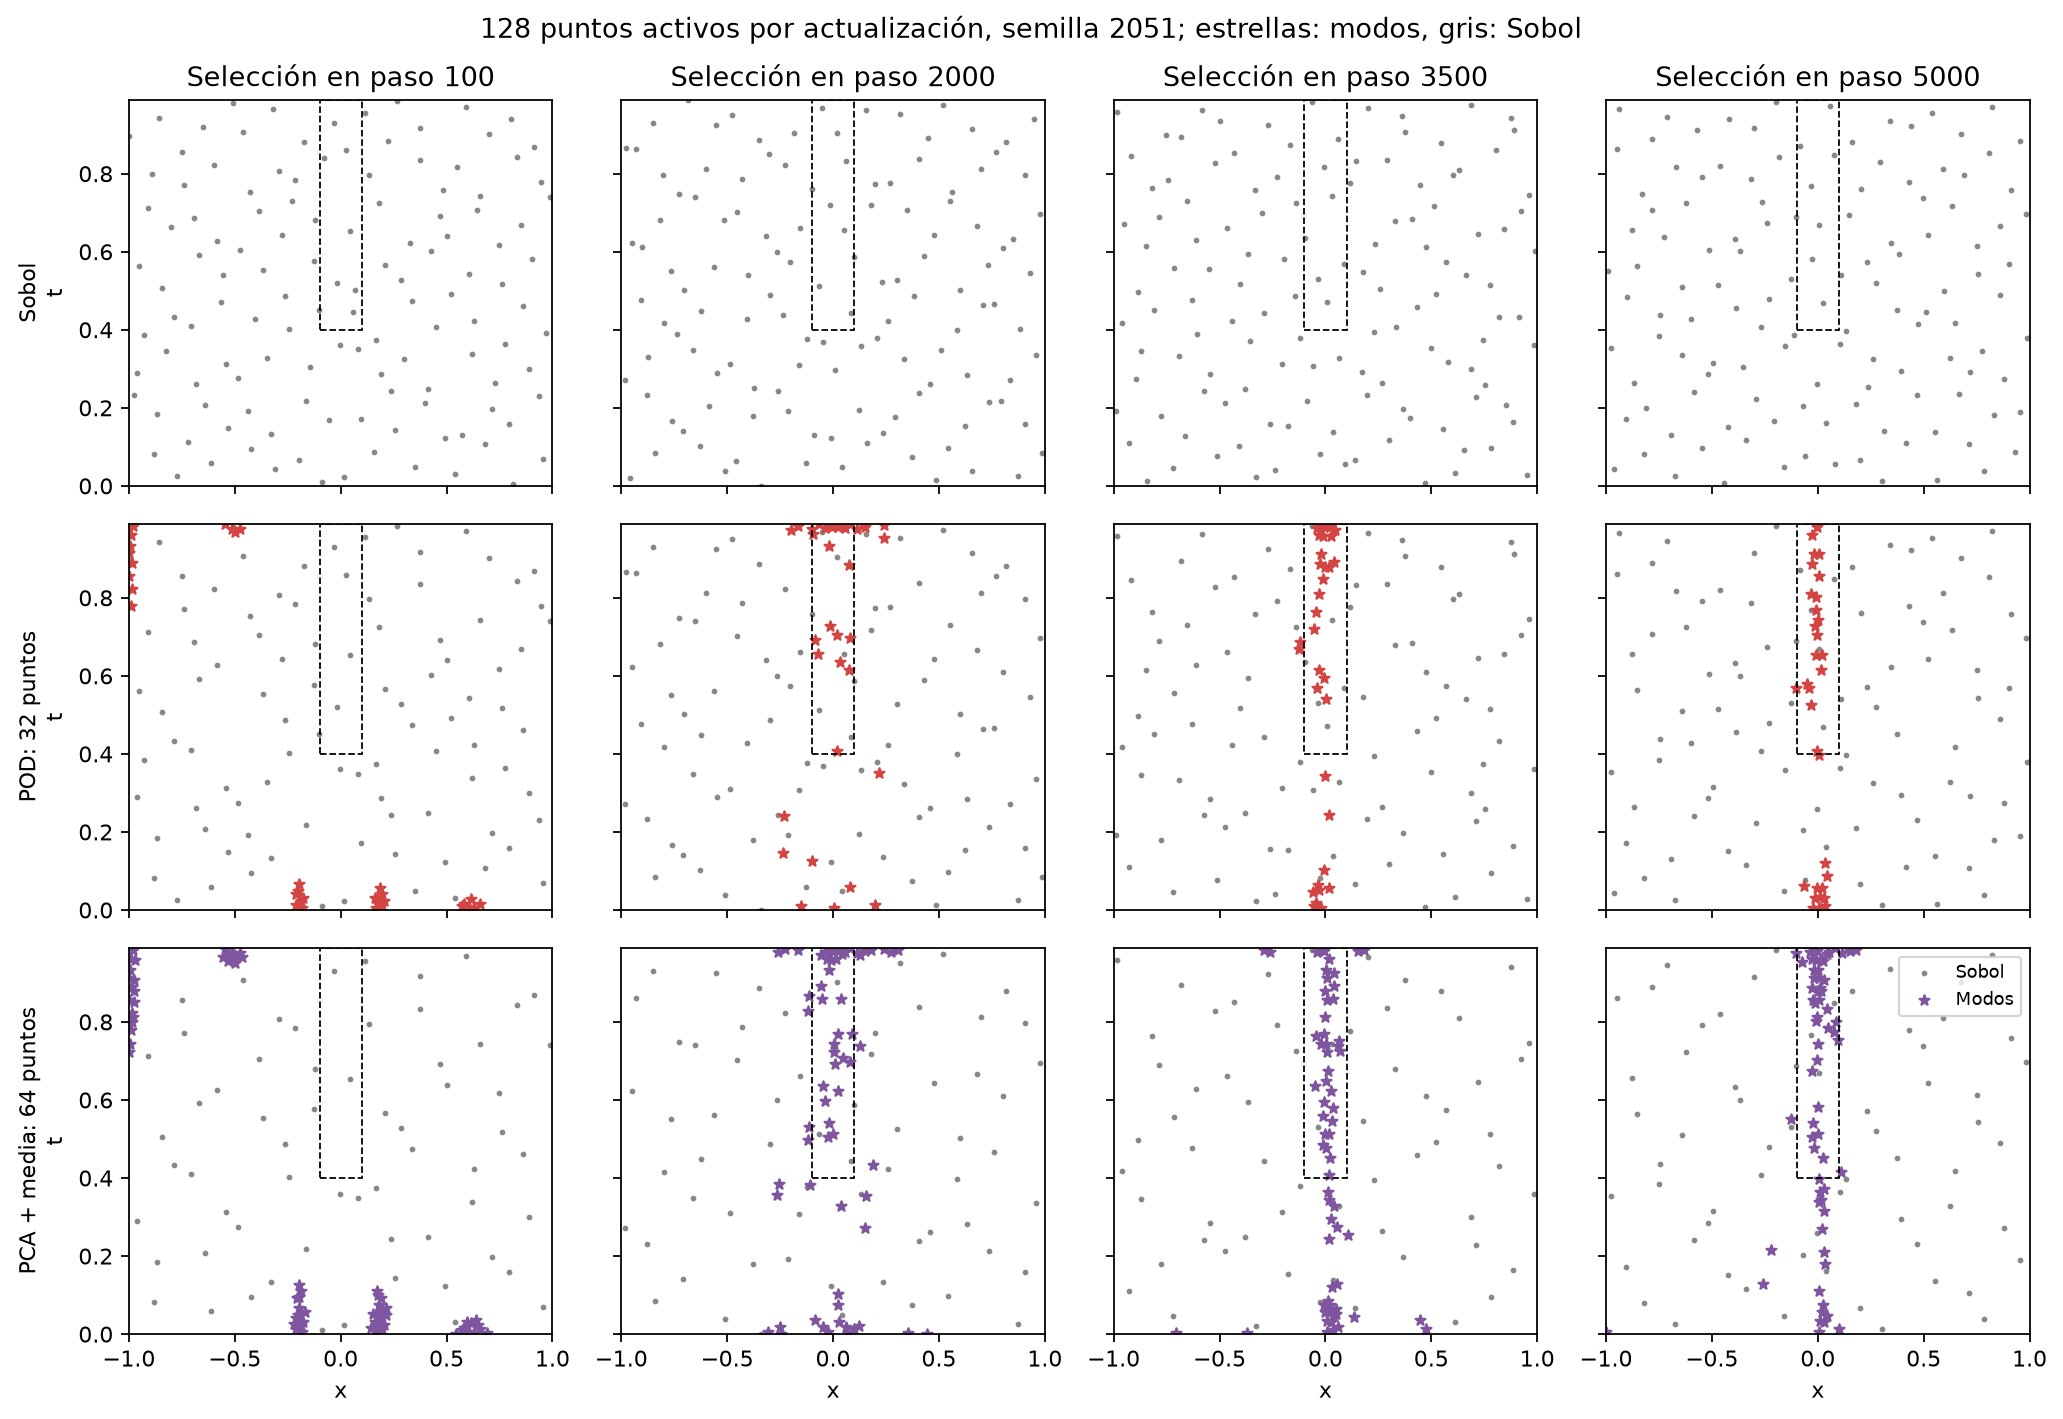

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/selected_points_evolution.png'), format='png', embed=True))


**Cobertura del dominio**

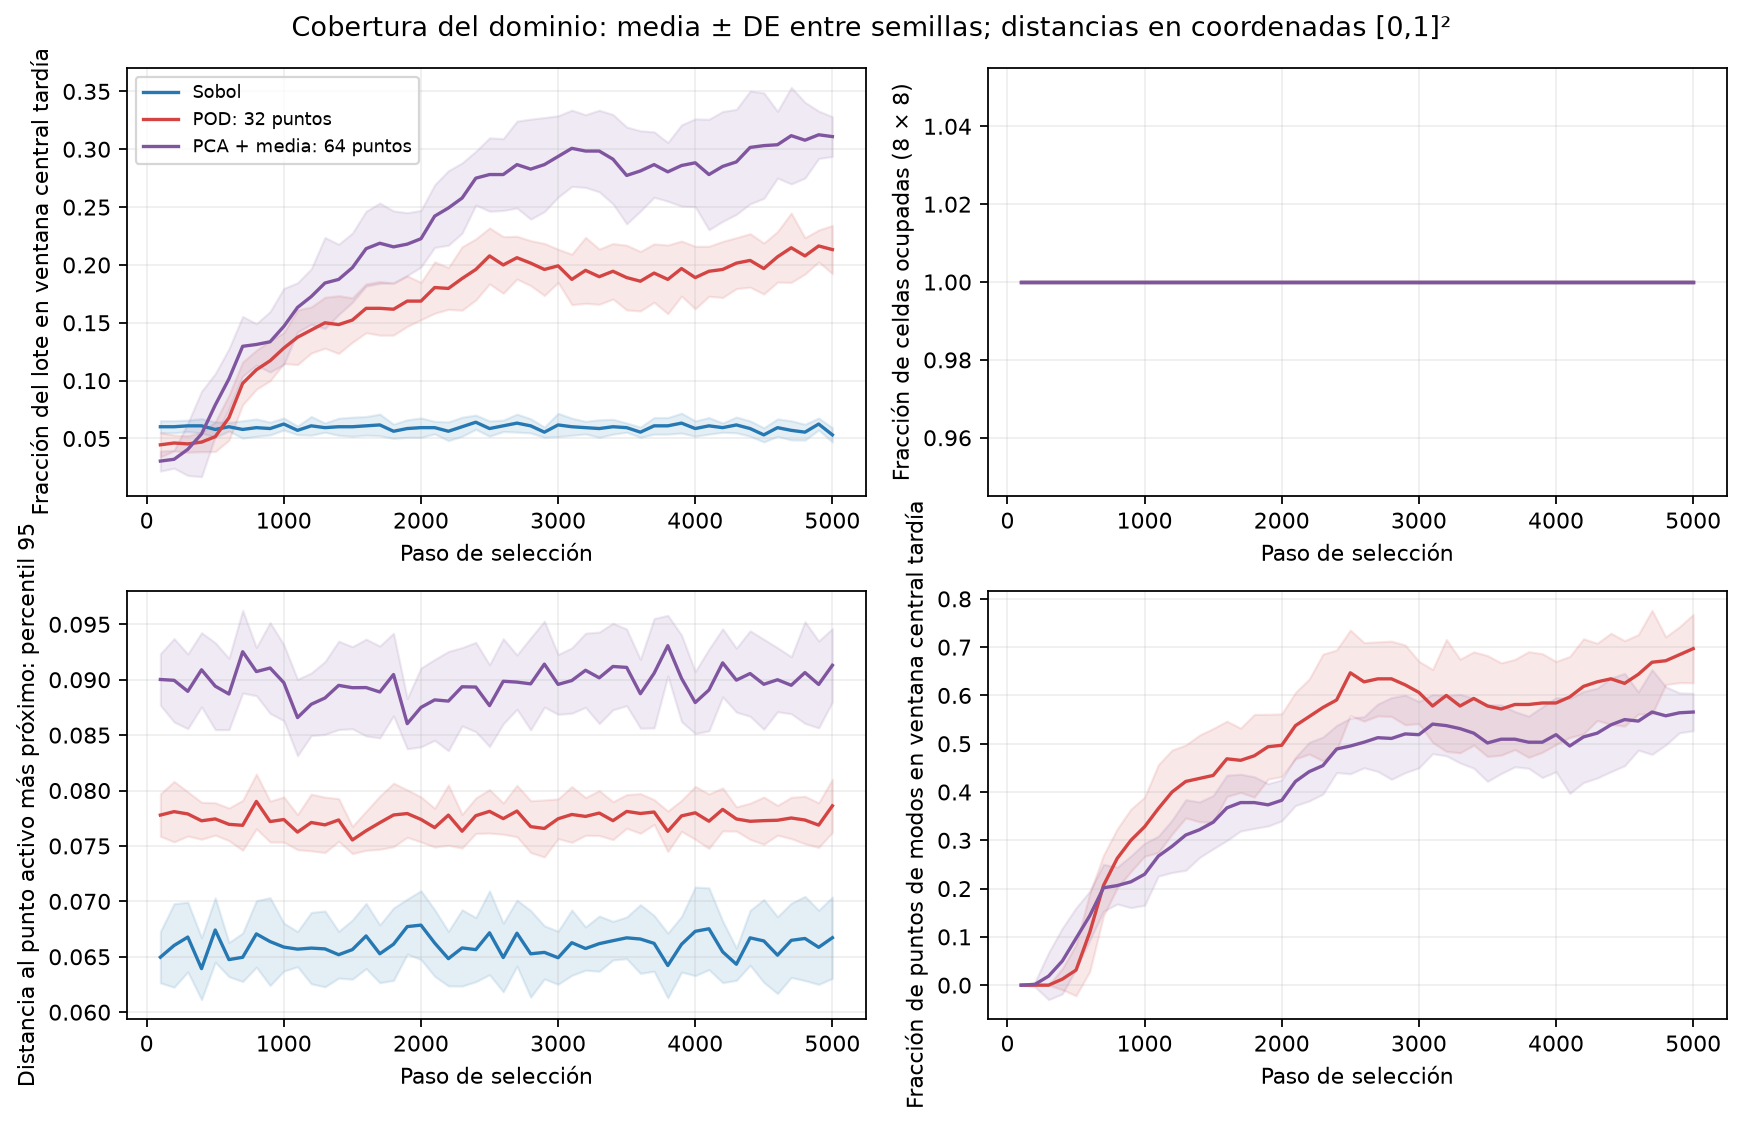

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/ic_long_budget/ic_uniform_domain_10_seeds_5k_v1/coverage_evolution.png'), format='png', embed=True))


## 7. Lectura del resultado

- **Sobol**: RMSE final 0.0913; mejora respecto a 2100 pasos en 10/10 semillas; residuo RMS independiente 0.3877.
- **POD: 32 puntos**: RMSE final 0.1188; mejora respecto a 2100 pasos en 10/10 semillas; residuo RMS independiente 0.1335.
- **PCA + media: 64 puntos**: RMSE final 0.1289; mejora respecto a 2100 pasos en 10/10 semillas; residuo RMS independiente 0.1374.
- Al presupuesto final, **POD: 32 puntos** tiene menor RMSE que Sobol en 2/10 semillas.
- Al presupuesto final, **PCA + media: 64 puntos** tiene menor RMSE que Sobol en 1/10 semillas.

Entrenar más mejora los resultados dentro de este protocolo. El método con mejor media de solución se distingue del que obtiene menor residuo, y las diferencias pareadas muestran cuántas semillas respaldan cada comparación. Estas observaciones se limitan al intervalo de presupuestos estudiado; no predicen que las curvas mantengan el mismo orden con presupuestos arbitrariamente mayores.

## 8. Reproducción y alcance

```powershell
python scripts/run_ic_long_budget.py
python scripts/run_ic_long_budget.py --report-only
```

`budget_metrics_by_seed.csv` guarda las métricas en los cuatro presupuestos; `budget_changes_by_seed.csv` conserva cambios pareados; `paired_gaps_vs_sobol.csv` resume las comparaciones entre métodos; `prefix_audit.csv` contrasta la trayectoria compartida con la corrida anterior. `summary.json` conserva las auditorías y huellas de las métricas de referencia. Cada semilla mantiene campos, parámetros, sondas y puntos activos.

Son diez semillas reutilizadas de un único problema Burgers. El objetivo de esta ronda es el efecto del presupuesto, con la distribución IC corregida. Los tiempos medidos incluyen instrumentación y no se usan para afirmar aceleración. Las figuras están incrustadas como PNG y exportadas como PNG/SVG. El [control anterior](11_ic_coverage_control.ipynb) documenta el punto de partida.